In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit

# Chargement
cols = ["unit", "cycle", "op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
train = pd.read_csv("data/train_FD001.txt", sep=r"\s+", header=None, names=cols)
test = pd.read_csv("data/test_FD001.txt", sep=r"\s+", header=None, names=cols)
rul_test = pd.read_csv("data/RUL_FD001.txt", header=None, names=["RUL"])

# RUL plafonnée à 125
max_cycle = train.groupby("unit")["cycle"].transform("max")
train["RUL"] = (max_cycle - train["cycle"]).clip(upper=125)

# Capteurs utiles
features = ["op1", "op2", "op3"] + [f"s{i}" for i in range(1, 22)]
std = train[features].std()
useful = std[std > 1e-6].index.tolist()

# Normalisation (fit sur le train uniquement)
scaler = StandardScaler()
train[useful] = scaler.fit_transform(train[useful])
test[useful] = scaler.transform(test[useful])

# Séparation train / validation par moteur
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, val_idx = next(gss.split(train, groups=train["unit"]))
X_tr, y_tr = train.iloc[tr_idx][useful], train.iloc[tr_idx]["RUL"]
X_val, y_val = train.iloc[val_idx][useful], train.iloc[val_idx]["RUL"]

# Test : dernière ligne de chaque moteur
X_test = test.groupby("unit").last()[useful]
y_test = rul_test["RUL"].clip(upper=125)

print(X_tr.shape, X_val.shape, X_test.shape)

(16561, 17) (4070, 17) (100, 17)


In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

def evaluate(model, X, y, name):
    pred = model.predict(X)
    rmse = np.sqrt(mean_squared_error(y, pred))
    mae = mean_absolute_error(y, pred)
    print(f"{name}: RMSE = {rmse:.2f} | MAE = {mae:.2f}")

mean_pred = np.full(len(y_val), y_tr.mean())
print("Moyenne (validation): RMSE =", round(np.sqrt(mean_squared_error(y_val, mean_pred)), 2))

lr = LinearRegression().fit(X_tr, y_tr)
evaluate(lr, X_val, y_val, "Linéaire (validation)")
evaluate(lr, X_test, y_test, "Linéaire (test)")

Moyenne (validation): RMSE = 41.72
Linéaire (validation): RMSE = 20.41 | MAE = 16.48
Linéaire (test): RMSE = 20.79 | MAE = 16.57


In [3]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)
evaluate(rf, X_val, y_val, "Random Forest (validation)")
evaluate(rf, X_test, y_test, "Random Forest (test)")

Random Forest (validation): RMSE = 17.01 | MAE = 12.35
Random Forest (test): RMSE = 17.11 | MAE = 11.91


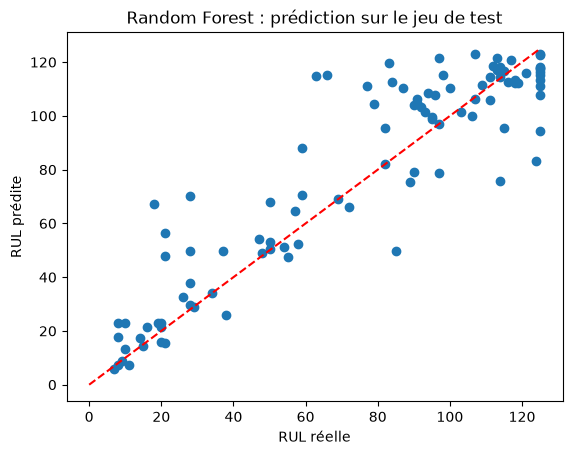

In [4]:
import matplotlib.pyplot as plt

pred = rf.predict(X_test)
plt.scatter(y_test, pred)
plt.plot([0, 125], [0, 125], "r--")
plt.xlabel("RUL réelle")
plt.ylabel("RUL prédite")
plt.title("Random Forest : prédiction sur le jeu de test")
plt.show()

In [5]:
from sklearn.ensemble import HistGradientBoostingRegressor

gb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)
gb.fit(X_tr, y_tr)
evaluate(gb, X_val, y_val, "Gradient Boosting (validation)")
evaluate(gb, X_test, y_test, "Gradient Boosting (test)")

Gradient Boosting (validation): RMSE = 16.90 | MAE = 12.30
Gradient Boosting (test): RMSE = 17.24 | MAE = 12.08


In [6]:
from sklearn.neural_network import MLPRegressor

nn = MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu",
                  early_stopping=True, validation_fraction=0.1,
                  max_iter=300, random_state=42)
nn.fit(X_tr, y_tr)
evaluate(nn, X_val, y_val, "Neural network (validation)")
evaluate(nn, X_test, y_test, "Neural network (test)")

Neural network (validation): RMSE = 16.73 | MAE = 12.14
Neural network (test): RMSE = 17.22 | MAE = 11.85


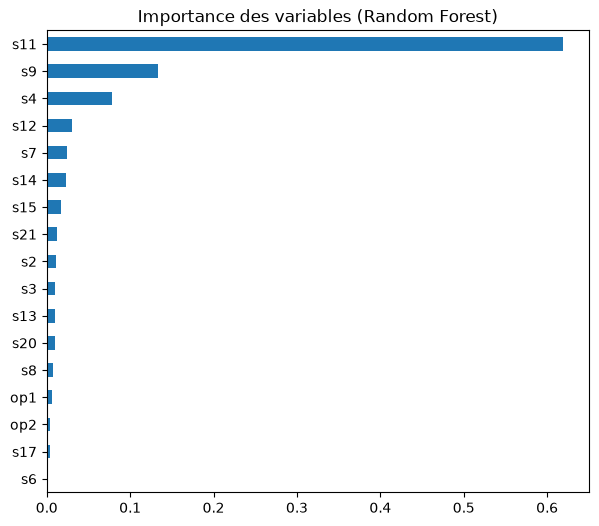

s11    0.619492
s9     0.133799
s4     0.077689
s12    0.030617
s7     0.023823
dtype: float64


In [7]:
import pandas as pd
import matplotlib.pyplot as plt

imp = pd.Series(rf.feature_importances_, index=useful).sort_values()
imp.plot(kind="barh", figsize=(7, 6))
plt.title("Importance des variables (Random Forest)")
plt.show()
print(imp.sort_values(ascending=False).head(5))